# Sky and source depth comparison by COSMOS field

Presentation: **2026-10-30**. Selection: archived baseline **d3c9272**, retaining
**`aper3_flags == 0`**. All magnitudes are AB magnitudes for a 3-arcsec-diameter
aperture. This notebook never reads the current no-flag-cut product trees.

Run all cells in order: load baseline inputs, calculate and save the CSV,
reload that CSV, then generate one grouped bar chart per band. No photometry,
matching, network query, or cross-field aggregation is performed.

## Definitions and table layout

- `band`: 20 bands, m400 through m875 in steps of 25 nm.
- The first 12 numeric columns contain, for COSMOS1 through COSMOS4 in order,
  `sky5snr_cosmosN_mag_avg`, `sky5snr_cosmosN_mag_sigma`, and
  `source5snr_cosmosN_mag`.
- Sky average: the arithmetic mean of **limiting magnitudes**, giving each
  valid grid cell equal weight. It is not an average of flux limits.
- Sky sigma: sample standard deviation (`ddof=1`) of those magnitudes.
  It describes spatial scatter, not the uncertainty on the average.
- The final 400 columns contain all 100 grid cells for each field:
  `sky5snr_mag_cosmosN_binK`, with `K = 10 * grid_row + grid_col + 1`.
  Thus bin1 is (row0, col0), bin10 is (row0, col9), and bin100 is (row9, col9).
  Grid rows increase with the image y coordinate.
- Only sky rows with `status == 'ok'` and a finite limiting magnitude enter
  the averages, scatter, and bin values. Invalid cells and unavailable bands
  remain explicit `NaN`, never zero. Empty fields have NaN summaries.
- Source depth: independently in each field, use baseline `matched` sources,
  S/N = 1.0857 / magnitude error, 0.25-mag bins with at least 10 sources,
  and the original baseline bright-to-faint S/N=5 crossing interpolation.
  No S/N >= 5 selection precedes this calculation. A missing crossing is NaN.
- Sky and source estimates have different spatial/sample weighting even
  within one field. Source depth is an error-based diagnostic of the selected
  matched sample, not a completeness measurement.

Each band plot has COSMOS1–4 on the x axis, paired Sky and Source bars, and
sky error bars of +/- one spatial sigma. Missing values are labeled N/A.

In [1]:
from pathlib import Path
import csv
import hashlib
import json

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from astropy.table import Table
from IPython.display import display, Image

def find_project_root():
    """Resolve the repository from a notebook or project-root working directory."""
    for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (candidate / 'output/experiments/aperture_flag_ablation/manifest.json').is_file():
            return candidate
    raise FileNotFoundError('Cannot locate the archived aperture-flag experiment.')

PROJECT_ROOT = find_project_root()
EXPERIMENT_ROOT = PROJECT_ROOT / 'output/experiments/aperture_flag_ablation'
BASELINE_ROOT = EXPERIMENT_ROOT / 'baseline/full_products'
OUTPUT_DIR = PROJECT_ROOT / 'Report/26-10-30/Depth'
PLOT_DIR = OUTPUT_DIR / 'depth_comparison_by_band'
CSV_PATH = OUTPUT_DIR / 'depth_comparison_baseline.csv'
BANDS = tuple(f'm{wavelength}' for wavelength in range(400, 900, 25))
FIELDS = (1, 2, 3, 4)
N_GRID_ROWS, N_GRID_COLS = 10, 10
N_GRID_CELLS = N_GRID_ROWS * N_GRID_COLS
EXPECTED_BASELINE_COMMIT = 'd3c9272'

manifest_path = EXPERIMENT_ROOT / 'manifest.json'
experiment_manifest = json.loads(manifest_path.read_text())
assert experiment_manifest['baseline_commit'] == EXPECTED_BASELINE_COMMIT
assert BASELINE_ROOT.is_dir()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

def decode_strings(column):
    """Normalize FITS byte/string labels without changing row identities."""
    return np.char.strip(np.asarray(column).astype(str))

def float_values(column):
    """Honor Astropy FITS masks; missing magnitude values must remain NaN."""
    return np.asarray(np.ma.filled(column, np.nan), dtype=float)

def sha256_file(path):
    """Record input fingerprints for provenance without copying large FITS files."""
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

sky_tables, master_tables, saved_source_tables = {}, {}, {}
input_provenance = []
for field in FIELDS:
    product_dir = BASELINE_ROOT / f'COSMOS{field}/singlephot'
    paths = {
        'sky_grid': product_dir / 'analysis' / f'cosmos{field}_7dt_depth_5sigma_3arcsec.csv',
        'master': product_dir / f'cosmos{field}_master_catalog.fits',
        'archived_source_depth': product_dir / 'analysis' / f'cosmos{field}_7dt_depth_all_band_m5sig_matched.fits',
    }
    for role, path in paths.items():
        assert path.is_file(), path
        assert path.is_relative_to(BASELINE_ROOT), path
        input_provenance.append({
            'field': field, 'role': role,
            'path': str(path.relative_to(PROJECT_ROOT)),
            'sha256': sha256_file(path),
        })
    sky_tables[field] = Table.read(paths['sky_grid'], format='ascii.csv')
    master_tables[field] = Table.read(paths['master'])
    saved_source_tables[field] = Table.read(paths['archived_source_depth'])

# Persist provenance in notebook metadata, keeping the CSV strictly within
# the user-requested numerical schema and avoiding an extra data file.
PROVENANCE = {
    'baseline_commit': EXPECTED_BASELINE_COMMIT,
    'selection': 'aper3_flags == 0',
    'sky_sigma_ddof': 1,
    'grid_bin_formula': '10 * grid_row + grid_col + 1',
    'source_snr_definition': '1.0857 / mag_err',
    'inputs': input_provenance,
}
print('Loaded archived flag-cut products for COSMOS1–4.')
print('Output:', OUTPUT_DIR)

Loaded archived flag-cut products for COSMOS1–4.
Output: /Users/mac_seo/Research_local/7DTonCOSMOS/Report/26-10-30/Depth


## Reproduce the original source-depth estimates

Recompute source depths from each baseline master, then require agreement
with its archived per-band depth table, including matched-source counts and
missing crossings. Source IDs are never joined across fields or catalog versions.

In [2]:
def baseline_sn5_crossing(centers, medians, level=5.0):
    """Reproduce the original baseline interpolation, including missing crossings.

    Preserve the original first-below-threshold rule rather than substituting
    a new fit or selecting S/N >= 5 sources, which would change the estimator.
    """
    centers = np.asarray(centers, dtype=float)
    medians = np.asarray(medians, dtype=float)
    finite = np.isfinite(centers) & np.isfinite(medians)
    centers, medians = centers[finite], medians[finite]
    if centers.size < 2:
        return np.nan
    order = np.argsort(centers)
    centers, medians = centers[order], medians[order]
    below = np.where(medians < level)[0]
    if below.size == 0 or np.all(medians < level):
        return np.nan
    index = int(below[0])
    if index == 0 or not (medians[index - 1] >= level > medians[index]):
        return np.nan
    x0, x1 = centers[index - 1:index + 1]
    y0, y1 = medians[index - 1:index + 1]
    return float(x0 + (level - y0) * (x1 - x0) / (y1 - y0))

def source_depth(master, band):
    """Calculate a field's matched-source depth using the archived binning rules."""
    magnitude_name, error_name = f'{band}_mag', f'{band}_mag_err'
    if magnitude_name not in master.colnames or error_name not in master.colnames:
        return np.nan, 0
    magnitude = float_values(master[magnitude_name])
    error = float_values(master[error_name])
    with np.errstate(divide='ignore', invalid='ignore'):
        snr = 1.0857 / error
    selected = (
        (decode_strings(master['master_class']) == 'matched')
        & np.isfinite(magnitude) & np.isfinite(snr) & (error > 0)
    )
    count = int(np.count_nonzero(selected))
    if count == 0:
        return np.nan, count
    mag, sn = magnitude[selected], snr[selected]
    edges = np.arange(np.floor(np.min(mag)), np.ceil(np.max(mag)) + 0.25, 0.25)
    centers, medians = [], []
    for left, right in zip(edges[:-1], edges[1:]):
        in_bin = (mag >= left) & (mag < right)
        if np.count_nonzero(in_bin) >= 10:
            centers.append((left + right) / 2)
            medians.append(float(np.median(sn[in_bin])))
    return baseline_sn5_crossing(centers, medians), count

source_depths = {}
validation_records = []
for field in FIELDS:
    archived = saved_source_tables[field]
    archived_bands = decode_strings(archived['band'])
    for band in BANDS:
        value, count = source_depth(master_tables[field], band)
        archived_rows = np.flatnonzero(archived_bands == band)
        assert len(archived_rows) <= 1, (field, band, 'duplicate archived band')
        if len(archived_rows):
            index = int(archived_rows[0])
            expected = float_values(archived['m5sig'])[index]
            assert np.isclose(value, expected, rtol=0, atol=1e-10, equal_nan=True), (field, band, value, expected)
            assert count == int(archived['n_matched'][index]), (field, band, count)
        else:
            assert count == 0 and np.isnan(value), (field, band)
        source_depths[(field, band)] = value
        validation_records.append((f'COSMOS{field}', band, count, value))

source_validation = Table(rows=validation_records, names=['field', 'band', 'n_matched', 'source5snr_mag'])
print('All source depths and matched counts reproduce the archived baseline.')
display(source_validation[np.asarray(source_validation['band']) == 'm600'])

All source depths and matched counts reproduce the archived baseline.


field,band,n_matched,source5snr_mag
str7,str4,int64,float64
COSMOS1,m600,1083,20.743100818948438
COSMOS2,m600,1488,21.07931776630172
COSMOS3,m600,355,nan
COSMOS4,m600,1472,21.676617927731073


## Build and save the 20-row, 413-column CSV

Join measurements by the exact **band name within each field**. The four
field grids stay separate, including overlapping sky areas. Require exactly
100 unique (row, column) cells for every available field-band grid.

In [3]:
summary_columns = [
    name
    for field in FIELDS
    for name in (
        f'sky5snr_cosmos{field}_mag_avg',
        f'sky5snr_cosmos{field}_mag_sigma',
        f'source5snr_cosmos{field}_mag',
    )
]
bin_columns = [
    f'sky5snr_mag_cosmos{field}_bin{bin_number}'
    for field in FIELDS
    for bin_number in range(1, N_GRID_CELLS + 1)
]
column_names = ['band', *summary_columns, *bin_columns]
assert len(column_names) == 413 and len(set(column_names)) == 413

output_rows = []
for band in BANDS:
    row = {'band': band, **{name: np.nan for name in column_names[1:]}}
    for field in FIELDS:
        sky = sky_tables[field]
        selected = np.flatnonzero(decode_strings(sky['band']) == band)
        cell_values = np.full(N_GRID_CELLS, np.nan)
        seen_cells = set()
        for index in selected:
            grid_row, grid_col = int(sky['grid_row'][index]), int(sky['grid_col'][index])
            assert 0 <= grid_row < N_GRID_ROWS and 0 <= grid_col < N_GRID_COLS
            cell_index = grid_row * N_GRID_COLS + grid_col
            assert cell_index not in seen_cells, (field, band, cell_index)
            seen_cells.add(cell_index)
            value = float(sky['depth_5sigma_mag'][index])
            if str(sky['status'][index]).strip() == 'ok' and np.isfinite(value):
                cell_values[cell_index] = value
        assert len(selected) in (0, N_GRID_CELLS), (field, band, len(selected))
        valid = cell_values[np.isfinite(cell_values)]
        if valid.size:
            row[f'sky5snr_cosmos{field}_mag_avg'] = float(np.mean(valid))
        if valid.size >= 2:
            row[f'sky5snr_cosmos{field}_mag_sigma'] = float(np.std(valid, ddof=1))
        row[f'source5snr_cosmos{field}_mag'] = source_depths[(field, band)]
        for cell_index, value in enumerate(cell_values):
            row[f'sky5snr_mag_cosmos{field}_bin{cell_index + 1}'] = float(value)
    output_rows.append(row)

# CSV uses explicit NaN text, preserving unavailable values distinctly from
# real numeric zero. Float representations retain the calculation precision.
with CSV_PATH.open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=column_names)
    writer.writeheader()
    for row in output_rows:
        writer.writerow({
            key: ('NaN' if key != 'band' and not np.isfinite(value) else value)
            for key, value in row.items()
        })
print(f'Saved CSV: {CSV_PATH.name}, {len(output_rows)} rows x {len(column_names)} columns')

Saved CSV: depth_comparison_baseline.csv, 20 rows x 413 columns


## Reload the saved CSV before plotting

The plot reads only this reloaded table. Recalculate each field's sky
average and sample standard deviation from its 100 saved bin columns to
check that summaries and details agree after CSV serialization.

In [4]:
with CSV_PATH.open(newline='', encoding='utf-8') as stream:
    reader = csv.DictReader(stream)
    assert reader.fieldnames == column_names
    reloaded = list(reader)
assert [row['band'] for row in reloaded] == list(BANDS)
plot_table = {
    row['band']: {name: float(row[name]) for name in column_names[1:]}
    for row in reloaded
}
for band in BANDS:
    row = plot_table[band]
    for field in FIELDS:
        cells = np.array([row[f'sky5snr_mag_cosmos{field}_bin{k}'] for k in range(1, 101)])
        valid = cells[np.isfinite(cells)]
        expected_avg = float(np.mean(valid)) if valid.size else np.nan
        expected_sigma = float(np.std(valid, ddof=1)) if valid.size >= 2 else np.nan
        assert np.isclose(row[f'sky5snr_cosmos{field}_mag_avg'], expected_avg, rtol=0, atol=1e-12, equal_nan=True)
        assert np.isclose(row[f'sky5snr_cosmos{field}_mag_sigma'], expected_sigma, rtol=0, atol=1e-12, equal_nan=True)
summary_table = Table(rows=[
    [band, *[plot_table[band][name] for name in summary_columns]] for band in BANDS
], names=['band', *summary_columns])
display(summary_table)
print('CSV round-trip and all 80 field-band sky summaries verified.')

band,sky5snr_cosmos1_mag_avg,sky5snr_cosmos1_mag_sigma,source5snr_cosmos1_mag,sky5snr_cosmos2_mag_avg,sky5snr_cosmos2_mag_sigma,source5snr_cosmos2_mag,sky5snr_cosmos3_mag_avg,sky5snr_cosmos3_mag_sigma,source5snr_cosmos3_mag,sky5snr_cosmos4_mag_avg,sky5snr_cosmos4_mag_sigma,source5snr_cosmos4_mag
str4,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
m400,21.063475068390062,0.07038688125218809,21.273398338607265,21.39152674449005,0.0672675096293193,21.53681459728209,19.466105824897745,0.06105783987312377,nan,21.886182747355733,0.04525886951655813,22.180959657951984
m425,21.81504409371936,0.08480418777222111,22.015279555128302,21.00812454624296,0.12001248464709133,21.199401439089527,19.94877672782675,0.05552867174583972,nan,21.025902064750493,0.05275897540541535,21.236465227821448
m450,21.071401719109428,0.10797211581928137,21.296042342198472,21.186334294218998,0.06431334271741537,21.355749385703533,13.61945617857289,0.051995964159952106,nan,nan,nan,nan
m475,21.749246806806976,0.08532882765069039,21.920497132324552,21.98771981349582,0.12054608428471911,22.274614898612594,21.19988295500342,0.24814258780059492,21.658916166011547,nan,nan,nan
m500,21.391879680597587,0.09120684676340948,21.533132718366303,21.737566724645916,0.0586317249424834,21.89291045058912,20.00088978672342,0.07580794863524846,20.093048103764254,22.168916029233728,0.05317105347473435,22.340642939249253
m525,21.786483778415867,0.07571752244885084,21.99636197060412,20.92103754589385,0.16930390585344357,21.199826302526933,20.278620480725934,0.0497330687910436,nan,21.102005245846044,0.046192368068611565,21.23688558143662
m550,20.674295735355773,0.21699371269685888,20.907209681143435,21.052688101096802,0.13327868772269155,21.17716861873753,19.55308827623977,0.09338581482079765,nan,21.557256459752416,0.17333699845018385,21.709001404956418
m575,21.404679082453214,0.05932575069123985,21.589116539387668,20.599312613163548,0.15934912852765704,20.90107004092718,20.060416608323752,0.054192981515575264,20.1621484579358,20.87853809991149,0.05346683751007483,20.983790304173592
m600,20.528990162263458,0.10295980180047751,20.743100818948438,20.935858170702843,0.056137365760204595,21.07931776630172,19.275484569126874,0.060221207866832084,nan,21.52550499332839,0.04993572282597127,21.676617927731073


CSV round-trip and all 80 field-band sky summaries verified.


## Create one grouped bar chart per band

Blue bars show each field's mean sky depth with +/- one spatial standard
deviation. Orange bars show its source-based depth. N/A marks unavailable
bands or an estimator without a valid result. All 20 figures use identical
magnitude limits and colors. The displayed magnitude axis is zoomed to the
data range; bar-height ratios have no physical meaning on this log scale.

Export PNG (220 dpi) for PowerPoint and vector PDF. Embed only the m600
example here to keep the executed notebook small.

Saved 20 band plots in PNG and PDF: /Users/mac_seo/Research_local/7DTonCOSMOS/Report/26-10-30/Depth/depth_comparison_by_band
All plots use a shared 12–24 AB magnitude range.


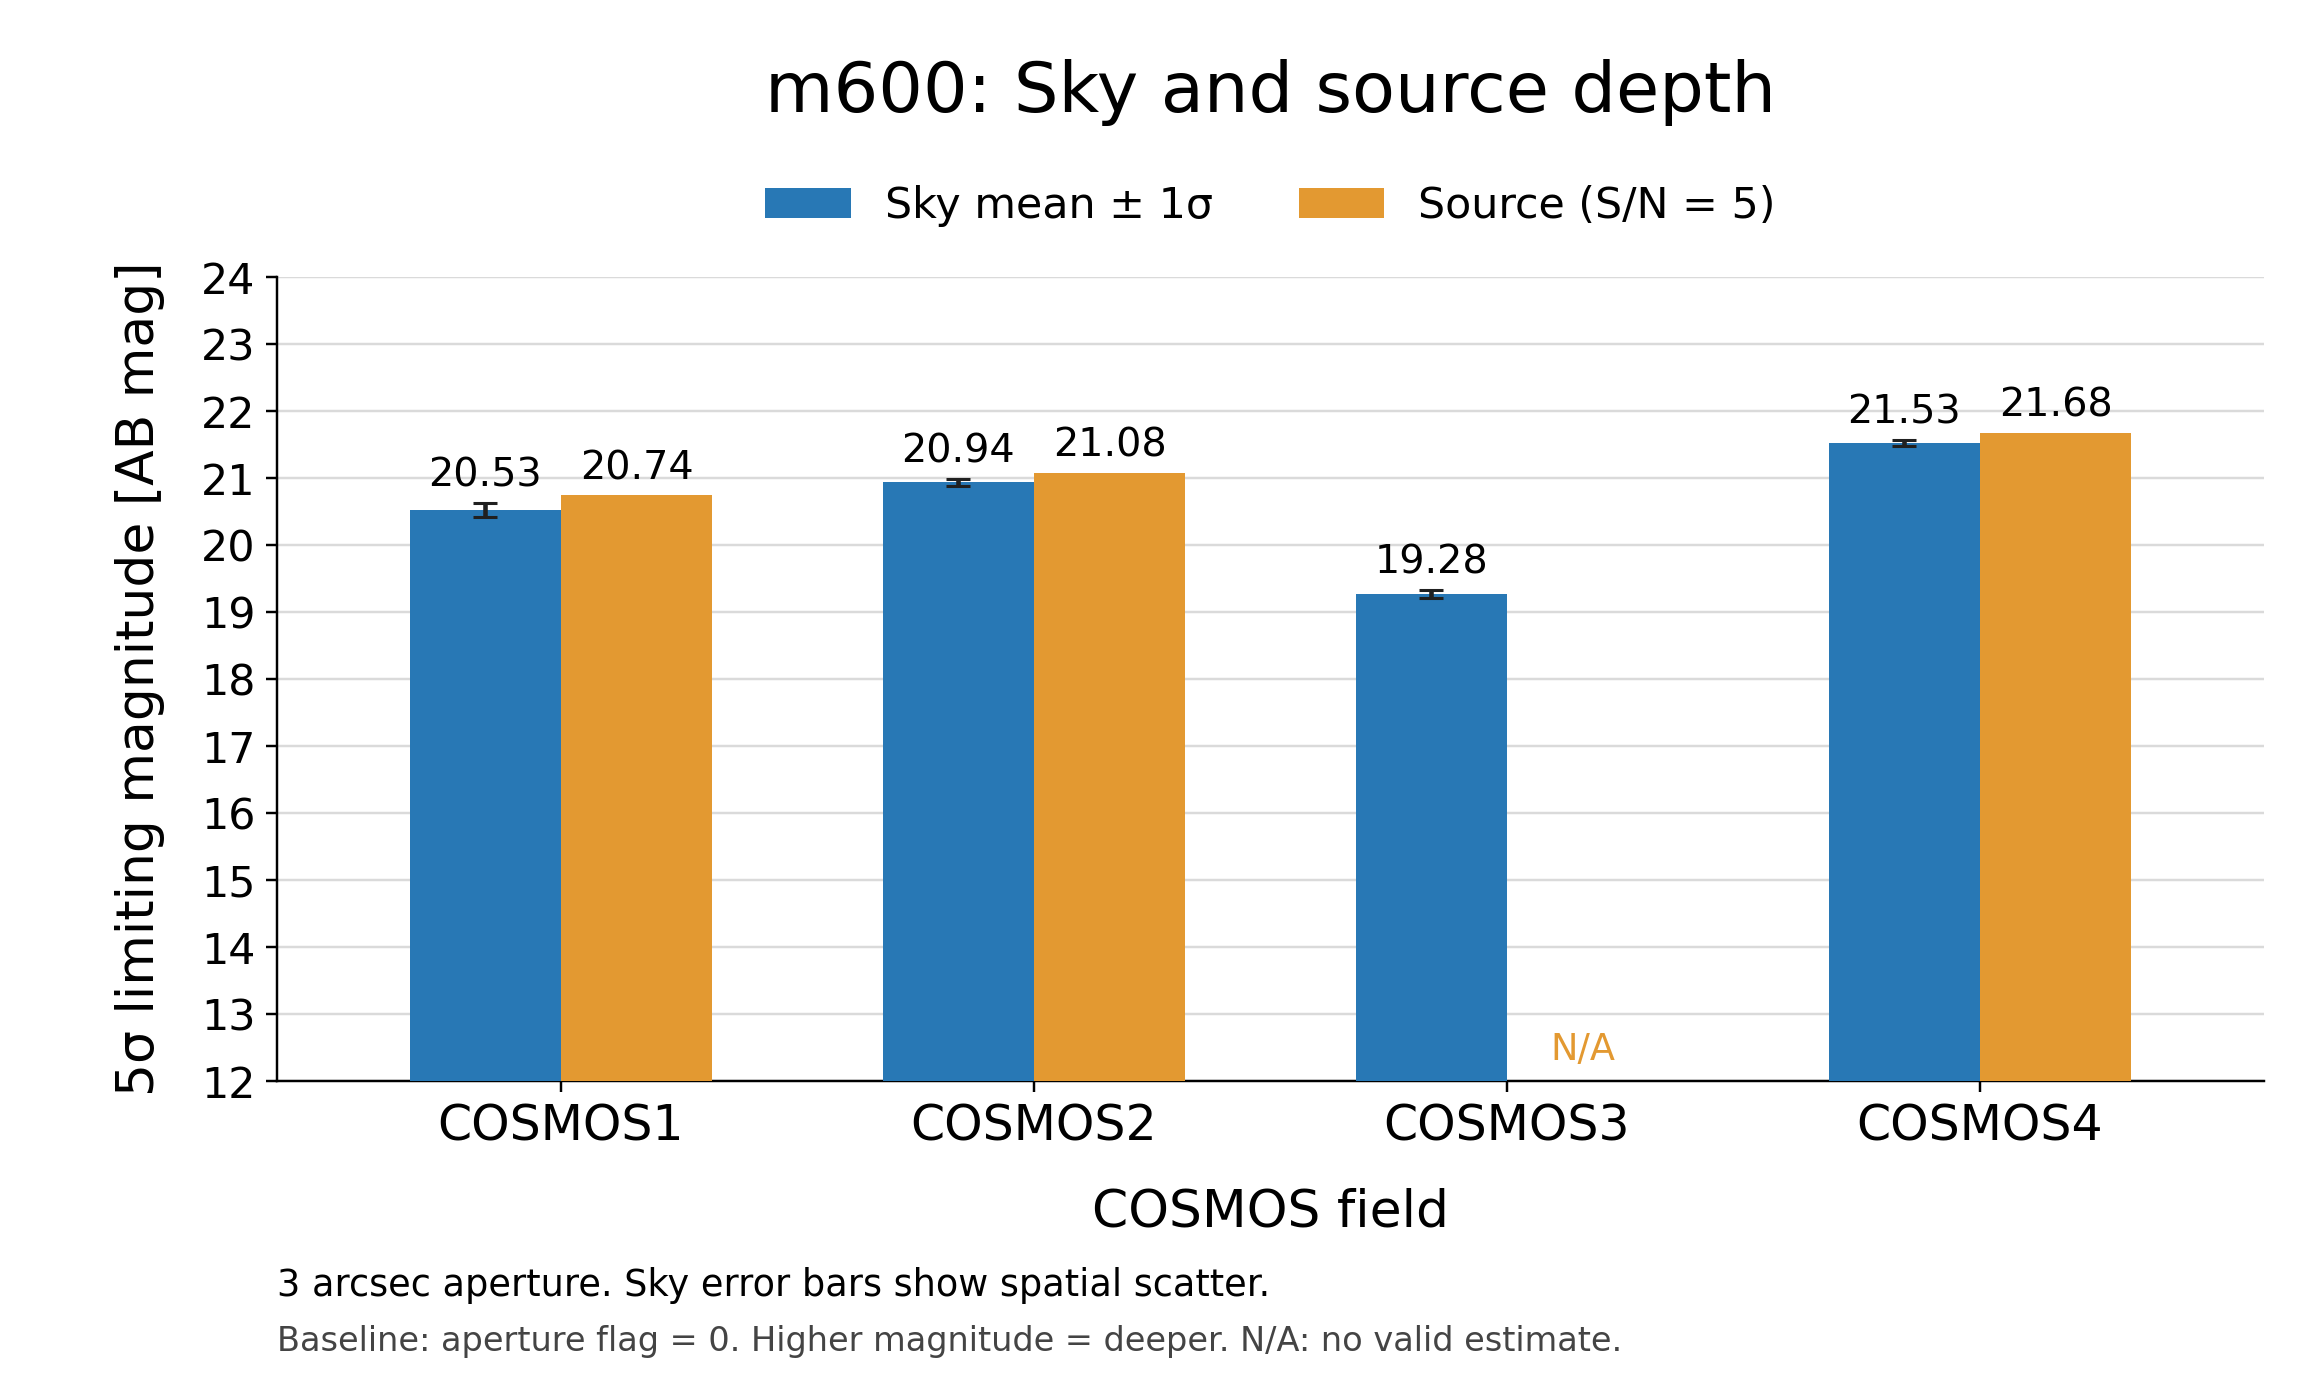

In [5]:
extrema = []
for band in BANDS:
    row = plot_table[band]
    for field in FIELDS:
        avg = row[f'sky5snr_cosmos{field}_mag_avg']
        sigma = row[f'sky5snr_cosmos{field}_mag_sigma']
        source = row[f'source5snr_cosmos{field}_mag']
        if np.isfinite(avg):
            spread = sigma if np.isfinite(sigma) else 0.0
            extrema.extend([avg - spread, avg + spread])
        if np.isfinite(source):
            extrema.append(source)
Y_MIN = float(np.floor(min(extrema)) - 1)
Y_MAX = float(np.ceil(max(extrema)) + 1)
COLORS = {'sky': '#2878B5', 'source': '#E39931'}
x = np.arange(len(FIELDS), dtype=float)
bar_width = 0.32
plot_paths = []

with plt.rc_context({
    'font.family': 'DejaVu Sans', 'font.size': 15,
    'axes.titlesize': 23, 'axes.labelsize': 17,
    'xtick.labelsize': 16, 'ytick.labelsize': 14,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
}):
    for band in BANDS:
        fig, ax = plt.subplots(figsize=(10.5, 6.3))
        fig.subplots_adjust(left=0.12, right=0.98, bottom=0.22, top=0.80)
        row = plot_table[band]
        for offset, field in enumerate(FIELDS):
            sky = row[f'sky5snr_cosmos{field}_mag_avg']
            sigma = row[f'sky5snr_cosmos{field}_mag_sigma']
            source = row[f'source5snr_cosmos{field}_mag']
            for kind, value, position in [
                ('sky', sky, x[offset] - bar_width / 2),
                ('source', source, x[offset] + bar_width / 2),
            ]:
                if np.isfinite(value):
                    error = sigma if kind == 'sky' and np.isfinite(sigma) else 0.0
                    # The shared visible magnitude range emphasizes actual
                    # magnitude differences, not a ratio of bar heights.
                    ax.bar(position, value - Y_MIN, bottom=Y_MIN,
                           width=bar_width, color=COLORS[kind], zorder=3)
                    if error > 0:
                        ax.errorbar(position, value, yerr=error, fmt='none',
                                    ecolor='#202020', capsize=4, linewidth=1.5, zorder=4)
                    ax.text(position, value + error + 0.12, f'{value:.2f}',
                            ha='center', va='bottom', fontsize=13)
                else:
                    ax.text(position, Y_MIN + 0.20, 'N/A', ha='center',
                            va='bottom', color=COLORS[kind], fontsize=12)
        ax.set_xticks(x, [f'COSMOS{field}' for field in FIELDS])
        ax.set_xlim(-0.60, len(FIELDS) - 0.40)
        ax.set_ylim(Y_MIN, Y_MAX)
        ax.set_yticks(np.arange(Y_MIN, Y_MAX + 0.5, 1.0))
        ax.set_xlabel('COSMOS field', labelpad=12)
        ax.set_ylabel('5σ limiting magnitude [AB mag]', labelpad=12)
        ax.set_title(f'{band}: Sky and source depth', pad=54)
        ax.grid(axis='y', color='#DADADA', linewidth=0.8, zorder=0)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(handles=[
            Patch(facecolor=COLORS['sky'], label='Sky mean ± 1σ'),
            Patch(facecolor=COLORS['source'], label='Source (S/N = 5)'),
        ], loc='lower center', bbox_to_anchor=(0.5, 1.015), ncol=2,
                  frameon=False, fontsize=14)
        fig.text(0.12, 0.065, '3 arcsec aperture. Sky error bars show spatial scatter.', fontsize=12)
        fig.text(0.12, 0.025, 'Baseline: aperture flag = 0. Higher magnitude = deeper. N/A: no valid estimate.', fontsize=11, color='#444444')
        stem = PLOT_DIR / f'{band}_sky_source_depth_baseline'
        fig.savefig(stem.with_suffix('.png'), dpi=220, facecolor='white')
        fig.savefig(stem.with_suffix('.pdf'), facecolor='white')
        plot_paths.extend([stem.with_suffix('.png'), stem.with_suffix('.pdf')])
        plt.close(fig)

assert len(plot_paths) == 40 and all(path.is_file() for path in plot_paths)
print(f'Saved 20 band plots in PNG and PDF: {PLOT_DIR}')
print(f'All plots use a shared {Y_MIN:.0f}–{Y_MAX:.0f} AB magnitude range.')
display(Image(filename=str(PLOT_DIR / 'm600_sky_source_depth_baseline.png')))

## Reproducibility record

Input paths below are relative to the project root. SHA-256 fingerprints
identify the exact archived inputs. The executed notebook retains the same
record in its `depth_comparison_provenance` metadata.

In [6]:
print(json.dumps(PROVENANCE, indent=2))
print('Completed: baseline-only input, 20 x 413 CSV, and 20 grouped bar charts.')

{
  "baseline_commit": "d3c9272",
  "selection": "aper3_flags == 0",
  "sky_sigma_ddof": 1,
  "grid_bin_formula": "10 * grid_row + grid_col + 1",
  "source_snr_definition": "1.0857 / mag_err",
  "inputs": [
    {
      "field": 1,
      "role": "sky_grid",
      "path": "output/experiments/aperture_flag_ablation/baseline/full_products/COSMOS1/singlephot/analysis/cosmos1_7dt_depth_5sigma_3arcsec.csv",
      "sha256": "a7e7df8d3ed29ee1a9b9bf9acf7b6ea0b9a82308853903f8a6144cd52fd221ef"
    },
    {
      "field": 1,
      "role": "master",
      "path": "output/experiments/aperture_flag_ablation/baseline/full_products/COSMOS1/singlephot/cosmos1_master_catalog.fits",
      "sha256": "a5a398e7a6e5ffd020109b22ca14b36924bae2e55d078425eacfb450f67ae46d"
    },
    {
      "field": 1,
      "role": "archived_source_depth",
      "path": "output/experiments/aperture_flag_ablation/baseline/full_products/COSMOS1/singlephot/analysis/cosmos1_7dt_depth_all_band_m5sig_matched.fits",
      "sha256": "7d7